In [1]:
import pandas as pd
print(pd.__version__)

3.0.6


In [ ]:
df = pd.read_csv("Appointments_GP_Regional_CSV_Aug_2026/Regional_CSV_SWLondon.csv") # reads the file and builds a table
df.head()
# df(dataframe) = name we chose for the table of data


,SUB_ICB_LOCATION_CODE,SUB_ICB_LOCATION_ONS_CODE,SUB_ICB_LOCATION_NAME,ICB_ONS_CODE,ICB_NAME,REGION_ONS_CODE,REGION_NAME,APPOINTMENT_MONTH,APPT_STATUS,HCP_TYPE,APPT_MODE,TIME_BETWEEN_BOOK_AND_APPT,COUNT_OF_APPOINTMENTS
0,36L,E38000245,NHS South West London ICB - 36L,E54000031,NHS South West London Integrated Care Board,E40000003,London,MAR2024,Attended,GP,Face-to-Face,1 Day,16328
1,36L,E38000245,NHS South West London ICB - 36L,E54000031,NHS South West London Integrated Care Board,E40000003,London,MAR2024,Attended,GP,Face-to-Face,15 to 21 Days,10414
2,36L,E38000245,NHS South West London ICB - 36L,E54000031,NHS South West London Integrated Care Board,E40000003,London,MAR2024,Attended,GP,Face-to-Face,2 to 7 Days,37921
3,36L,E38000245,NHS South West London ICB - 36L,E54000031,NHS South West London Integrated Care Board,E40000003,London,MAR2024,Attended,GP,Face-to-Face,22 to 28 Days,5065
4,36L,E38000245,NHS South West London ICB - 36L,E54000031,NHS South West London Integrated Care Board,E40000003,London,MAR2024,Attended,GP,Face-to-Face,8 to 14 Days,27168


In [ ]:
import os # built in python module conected to operating system
print(os.getcwd()) # prints folder python working on, get current working directory
print(os.listdir(".")) # lists everything in that folder (dot means "right here")

c:\Users\tiffa\OneDrive\Desktop\gp-data-project
['Appointments_GP_Regional_CSV_Aug_2026', 'gp_appointments.ipynb', 'venv']


In [4]:
print(os.listdir("Appointments_GP_Regional_CSV_Aug_2026"))

['Regional_CSV_BathNESomSwindonWilts.csv', 'Regional_CSV_BirminghamSolihull.csv', 'Regional_CSV_BlackCountry.csv', 'Regional_CSV_BristolNSomSGloucs.csv', 'Regional_CSV_CentralEast.csv', 'Regional_CSV_CheshireMerseyside.csv', 'Regional_CSV_CornwallIoS.csv', 'Regional_CSV_CoventryWarwickshire.csv', 'Regional_CSV_DerbyDerbyshire.csv', 'Regional_CSV_Devon.csv', 'Regional_CSV_Dorset.csv', 'Regional_CSV_Essex.csv', 'Regional_CSV_Gloucestershire.csv', 'Regional_CSV_GManchesterHSCP.csv', 'Regional_CSV_HampshireIoW.csv', 'Regional_CSV_HereWorcs.csv', 'Regional_CSV_HumberNYorks.csv', 'Regional_CSV_KentMedway.csv', 'Regional_CSV_LancsSCumbria.csv', 'Regional_CSV_LeicesterLshire.csv', 'Regional_CSV_Lincolnshire.csv', 'Regional_CSV_NELondon.csv', 'Regional_CSV_NENCumbria.csv', 'Regional_CSV_NorfolkSuffolk.csv', 'Regional_CSV_Northamptonshire.csv', 'Regional_CSV_NottinghamNotts.csv', 'Regional_CSV_SELondon.csv', 'Regional_CSV_ShropsTelfordWrekin.csv', 'Regional_CSV_Somerset.csv', 'Regional_CSV_Staff

In [5]:
path = "Appointments_GP_Regional_CSV_Aug_2026/Regional_CSV_SWLondon.csv"
print(os.path.exists(path)) # is there anything in this file?
print(os.path.isfile(path)) # is it a file, not a folder

True
True


In [9]:
print(df.shape) # prints (rows,colums)
print(df.columns.tolist()) #lists every column name

(7596, 13)
['SUB_ICB_LOCATION_CODE', 'SUB_ICB_LOCATION_ONS_CODE', 'SUB_ICB_LOCATION_NAME', 'ICB_ONS_CODE', 'ICB_NAME', 'REGION_ONS_CODE', 'REGION_NAME', 'APPOINTMENT_MONTH', 'APPT_STATUS', 'HCP_TYPE', 'APPT_MODE', 'TIME_BETWEEN_BOOK_AND_APPT', 'COUNT_OF_APPOINTMENTS']


In [11]:
print(df.dtypes) #shows data type of each column
print(df["APPT_STATUS"].unique()) # lists different valies in a column, no repeats
print(df["APPOINTMENT_MONTH"].unique()[:5]) #last part keeps the first 5 

SUB_ICB_LOCATION_CODE           str
SUB_ICB_LOCATION_ONS_CODE       str
SUB_ICB_LOCATION_NAME           str
ICB_ONS_CODE                    str
ICB_NAME                        str
REGION_ONS_CODE                 str
REGION_NAME                     str
APPOINTMENT_MONTH               str
APPT_STATUS                     str
HCP_TYPE                        str
APPT_MODE                       str
TIME_BETWEEN_BOOK_AND_APPT      str
COUNT_OF_APPOINTMENTS         int64
dtype: object
<StringArray>
['Attended', 'DNA', 'Unknown']
Length: 3, dtype: str
<StringArray>
['MAR2024', 'APR2024', 'MAY2024', 'JUN2024', 'JUL2024']
Length: 5, dtype: str


In [12]:
df["month"] = pd.to_datetime(df["APPOINTMENT_MONTH"], format="%b%Y") 
print(df["month"].head())
# the pd.to_datetime(--) converte tet into real dates 
# format = "%b%Y" tells pands the pattern %b is a short month name and %Y is a 4 digit year

0   2024-03-01
1   2024-03-01
2   2024-03-01
3   2024-03-01
4   2024-03-01
Name: month, dtype: datetime64[us]


In [13]:
monthly = df.groupby("month")["COUNT_OF_APPOINTMENTS"].sum()
#puts rows with same month in a grp, says whoch columns to look inside each group

print(monthly.head()) # adds up the numbers in each grp

month
2024-03-01    719732
2024-04-01    730851
2024-05-01    735609
2024-06-01    696873
2024-07-01    749618
Name: COUNT_OF_APPOINTMENTS, dtype: int64


In [14]:
df["COUNT_OF_APPOINTMENTS"].sum()

np.int64(22093893)

In [16]:
df.groupby("month")["COUNT_OF_APPOINTMENTS"].sum()

month
2024-03-01    719732
2024-04-01    730851
2024-05-01    735609
2024-06-01    696873
2024-07-01    749618
2024-08-01    662887
2024-09-01    720041
2024-10-01    868953
2024-11-01    743751
2024-12-01    658552
2025-01-01    776768
2025-02-01    700857
2025-03-01    738301
2025-04-01    680274
2025-05-01    697885
2025-06-01    730623
2025-07-01    770629
2025-08-01    646646
2025-09-01    760592
2025-10-01    883522
2025-11-01    727734
2025-12-01    715857
2026-01-01    766793
2026-02-01    730641
2026-03-01    810301
2026-04-01    726057
2026-05-01    683428
2026-06-01    792775
2026-07-01    794251
2026-08-01    673092
Name: COUNT_OF_APPOINTMENTS, dtype: int64

Matplotlib is building the font cache; this may take a moment.


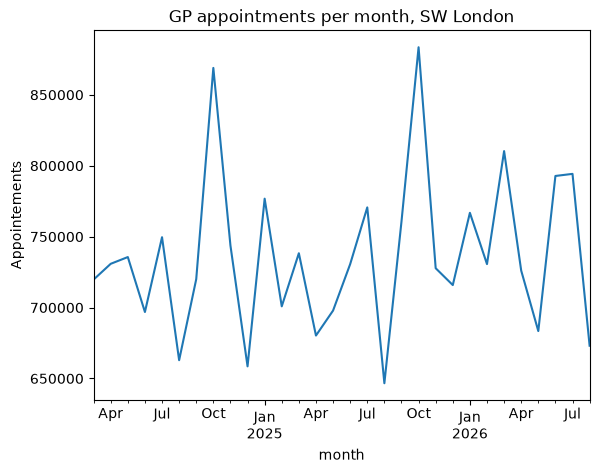

In [ ]:
import matplotlib.pyplot as plt

monthly =df.groupby("month")["COUNT_OF_APPOINTMENTS"].sum() # one total per month
monthly.plot(title="GP appointments per month, SW London") # draw them, the .plot puts monthd on the bottom, totals as the side
#title = is the heading
plt.ylabel("Appointements") # labels the side
plt.show() # displays it


In [18]:
by_mode = df.groupby("APPT_MODE")["COUNT_OF_APPOINTMENTS"].sum()
print(by_mode)

APPT_MODE
Face-to-Face    12780357
Home Visit        261748
Telephone        6196795
Unknown           221630
Video/Online     2633363
Name: COUNT_OF_APPOINTMENTS, dtype: int64


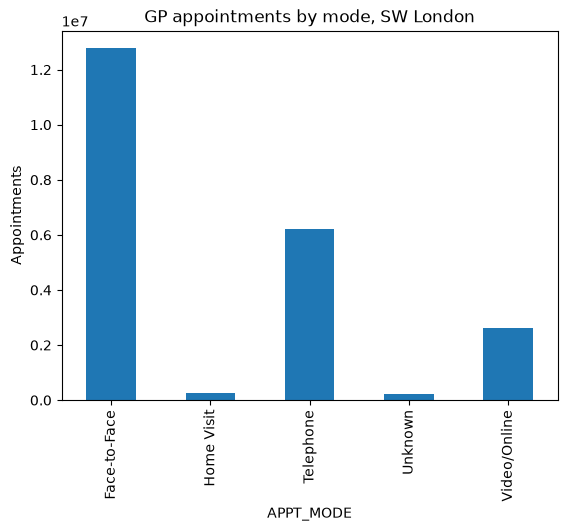

In [20]:
by_mode.plot(kind="bar", title="GP appointments by mode, SW London")
plt.ylabel("Appointments")
plt.show()